# Tutorial: Gaussian-Linear Hidden Markov Model
https://glhmm.readthedocs.io/en/latest/notebooks/GLHMM_example.html

**Example: Modelling time-varying interaction between brain and physiological data**

We will now go through an example illustrating how to fit and inspect a GLHMM. The example uses simulated data that can be found in the example_data folder. The data were generated to resemble one set of fMRI timeseries and two corresponding non-brain physiological (e.g., heart rate and respiration) timeseries. Our goal is to estimate time-varying amplitude and functional connectivity (FC) within the fMRI recordings and temporal changes in the relationship between the fMRI and the physiological data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from glhmm import glhmm, preproc, utils, graphics

brain_data = pd.read_csv('./GLHMM-example-data/data.csv', header=None).to_numpy()
phys_data = pd.read_csv('./GLHMM-example-data/dataX.csv', header=None).to_numpy()
T_t = pd.read_csv('./GLHMM-example-data/T.csv', header=None).to_numpy()

In [2]:
brain_data,_,preproclogY = preproc.preprocess_data(brain_data, T_t)
phys_data,_,preproclogX = preproc.preprocess_data(phys_data, T_t)

**Initialise and train a GLHMM**

In [3]:
brainphys_glhmm = glhmm.glhmm(model_beta='state', K=4, covtype='full', preproclogX=preproclogX, preproclogY=preproclogY)
print(brainphys_glhmm.hyperparameters)


{'K': 4, 'covtype': 'full', 'model_mean': 'state', 'model_beta': 'state', 'dirichlet_diag': 10, 'connectivity': None, 'Pstructure': array([[ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True],
       [ True,  True,  True,  True]]), 'Pistructure': array([ True,  True,  True,  True])}


In [4]:
np.random.seed(123)
brainphys_glhmm.train(X=phys_data, Y=brain_data, indices=T_t)

Init repetition 1 free energy = 1381128.6016174965
Init repetition 2 free energy = 1382091.9084582604
Init repetition 3 free energy = 1382299.4791453683
Init repetition 4 free energy = 1381059.3458221399
Init repetition 5 free energy = 1381870.580908006
Best repetition: 4
Cycle 1 free energy = 1381021.2570320976
Cycle 2 free energy = 1380314.0855438116
Cycle 3, free energy = 1379972.6902552778, relative change = 0.3255827822136377
Cycle 4, free energy = 1379637.8107843904, relative change = 0.24206178696308545
Cycle 5, free energy = 1379339.0544060403, relative change = 0.1775983307375493
Cycle 6, free energy = 1379102.7130229976, relative change = 0.12318788723205827
Cycle 7, free energy = 1378906.2905810836, relative change = 0.09287260411143314
Cycle 8, free energy = 1378757.9604047453, relative change = 0.065537223245831
Cycle 9, free energy = 1378628.688765123, relative change = 0.05403049158791607
Cycle 10, free energy = 1378511.2147324914, relative change = 0.046801614717824847


(array([[9.68162761e-06, 7.13675619e-05, 9.99885754e-01, 3.31970643e-05],
        [9.24614870e-05, 1.00657287e-04, 9.99277233e-01, 5.29648690e-04],
        [1.91538028e-05, 4.77427971e-05, 9.94426518e-01, 5.50658584e-03],
        ...,
        [7.49804786e-08, 5.20196319e-01, 4.79799950e-01, 3.65609577e-06],
        [2.93298705e-07, 8.77263650e-03, 9.91222068e-01, 5.00269046e-06],
        [3.96313619e-06, 8.45247928e-05, 9.99873161e-01, 3.83506608e-05]],
       shape=(20000, 4)),
 array([[[5.59612739e-07, 1.35912294e-08, 9.02678196e-06, 8.16416757e-08],
         [2.74155920e-08, 5.87135634e-06, 6.51270992e-05, 3.41690811e-07],
         [9.18179605e-05, 9.46388557e-05, 9.99183518e-01, 5.15779382e-04],
         [5.64981123e-08, 1.33483523e-07, 1.95611073e-05, 1.34459753e-05]],
 
        [[1.02956395e-06, 5.85409895e-08, 8.39283959e-05, 7.44498613e-06],
         [7.66884002e-09, 3.84508610e-06, 9.20670060e-05, 4.73752590e-06],
         [1.80774889e-05, 4.36229992e-05, 9.94182141e-01, 5.033

**Inspect model: Interaction between brain and physiological measures**

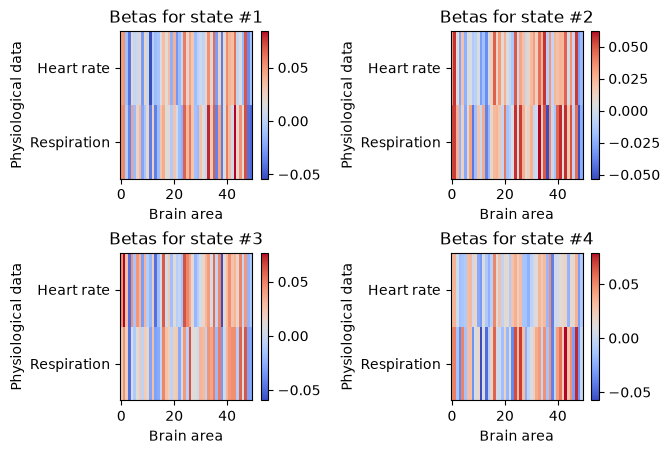

In [5]:
K = brainphys_glhmm.hyperparameters["K"] # the number of states
q = brain_data.shape[1] # the number of parcels/channels
state_betas = np.zeros(shape=(2,q,K))
state_betas = brainphys_glhmm.get_betas()

cmap = "coolwarm"
ytick =["Heart rate", "Respiration"]
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(state_betas[:,:,k], cmap=cmap,aspect='auto', interpolation='none')
    plt.colorbar()
    plt.ylabel('Physiological data')
    plt.yticks(np.arange(2), ytick)
    plt.xlabel('Brain area')
    plt.title(f"Betas for state #{k+1}")
plt.subplots_adjust(hspace=0.5, wspace=1)
plt.show()

**State means and covariances**

In [6]:
state_means = np.zeros(shape=(q, K))
for k in range(K):
    state_means[:,k] = brainphys_glhmm.get_mean(k) # the state means in the shape (no. features, no. states)
state_FC = np.zeros(shape=(q, q, K))
for k in range(K):
    state_FC[:,:,k] = brainphys_glhmm.get_covariance_matrix(k=k) # the state covariance matrices

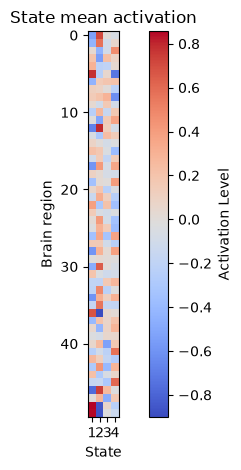

In [7]:
plt.imshow(state_means,cmap=cmap, interpolation="none")
plt.colorbar(label='Activation Level') # Label for color bar
plt.title("State mean activation")
plt.xticks(np.arange(K), np.arange(1,K+1))
plt.gca().set_xlabel('State')
plt.gca().set_ylabel('Brain region')
plt.tight_layout()  # Adjust layout for better spacing
plt.show()

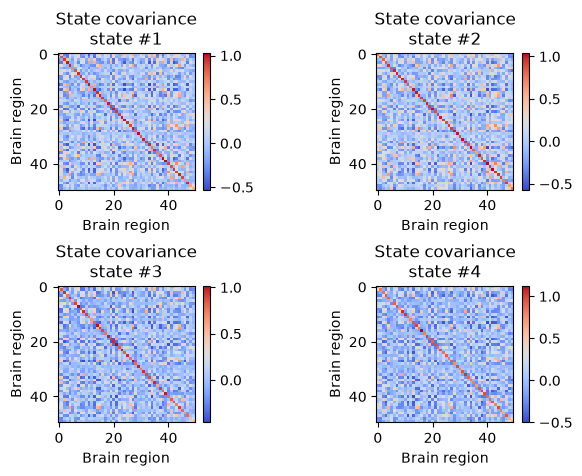

In [8]:
for k in range(K):
    plt.subplot(2,2,k+1)
    plt.imshow(state_FC[:,:,k], cmap=cmap, interpolation="none")
    plt.xlabel('Brain region')
    plt.ylabel('Brain region')
    plt.colorbar()
    plt.title("State covariance\nstate #%s" % (k+1))
plt.subplots_adjust(hspace=0.7, wspace=0.8)
plt.show()

**Dynamics: Transition probabilities and Viterbi path**

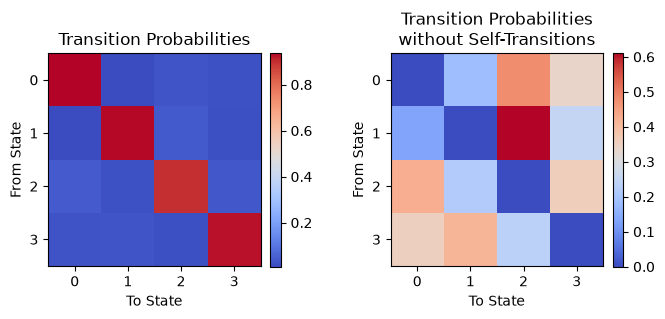

In [9]:
TP = brainphys_glhmm.P.copy() # the transition probability matrix

# Plot Transition Probabilities
plt.figure(figsize=(7, 4))

# Plot 1: Full Transition Probabilities
plt.subplot(1, 2, 1)
plt.imshow(TP, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

# Plot 2: Transition Probabilities without Self-Transitions
TP_noself = TP - np.diag(np.diag(TP))  # Remove self-transitions
TP_noself2 = TP_noself / TP_noself.sum(axis=1, keepdims=True)  # Normalize probabilities
plt.subplot(1, 2, 2)
plt.imshow(TP_noself2, cmap=cmap, interpolation='nearest')  # Improved color mapping
plt.title('Transition Probabilities\nwithout Self-Transitions')
plt.xlabel('To State')
plt.ylabel('From State')
plt.colorbar(fraction=0.046, pad=0.04)

plt.tight_layout()  # Adjust layout for better spacing
plt.show()

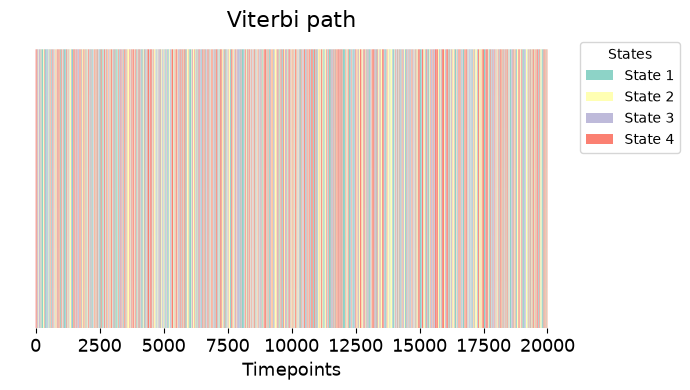

In [10]:
vpath = brainphys_glhmm.decode(X=phys_data, Y=brain_data, indices=T_t, viterbi=True)
graphics.plot_vpath(vpath, title="Viterbi path")
